Pytorch

Epoch: 1, Loss: 0.06137813255190849
Epoch: 2, Loss: 0.06133873015642166
Epoch: 3, Loss: 0.06130001321434975
Epoch: 4, Loss: 0.06126197427511215
Epoch: 5, Loss: 0.06122460588812828
Epoch: 6, Loss: 0.06118788197636604
Epoch: 7, Loss: 0.061151809990406036
Epoch: 8, Loss: 0.061116378754377365
Epoch: 9, Loss: 0.06108156219124794
Epoch: 10, Loss: 0.06104736402630806
Epoch: 11, Loss: 0.06101376935839653
Epoch: 12, Loss: 0.060980770736932755
Epoch: 13, Loss: 0.06094835698604584
Epoch: 14, Loss: 0.06091652438044548
Epoch: 15, Loss: 0.06088525056838989
Epoch: 16, Loss: 0.06085454672574997
Epoch: 17, Loss: 0.06082438305020332
Epoch: 18, Loss: 0.060794759541749954
Epoch: 19, Loss: 0.060765668749809265
Epoch: 20, Loss: 0.06073709577322006
Epoch: 21, Loss: 0.06070903688669205
Epoch: 22, Loss: 0.06068148463964462
Epoch: 23, Loss: 0.06065443530678749
Epoch: 24, Loss: 0.060627859085798264
Epoch: 25, Loss: 0.06060177460312843
Epoch: 26, Loss: 0.06057615205645561
Epoch: 27, Loss: 0.060551002621650696
Epo

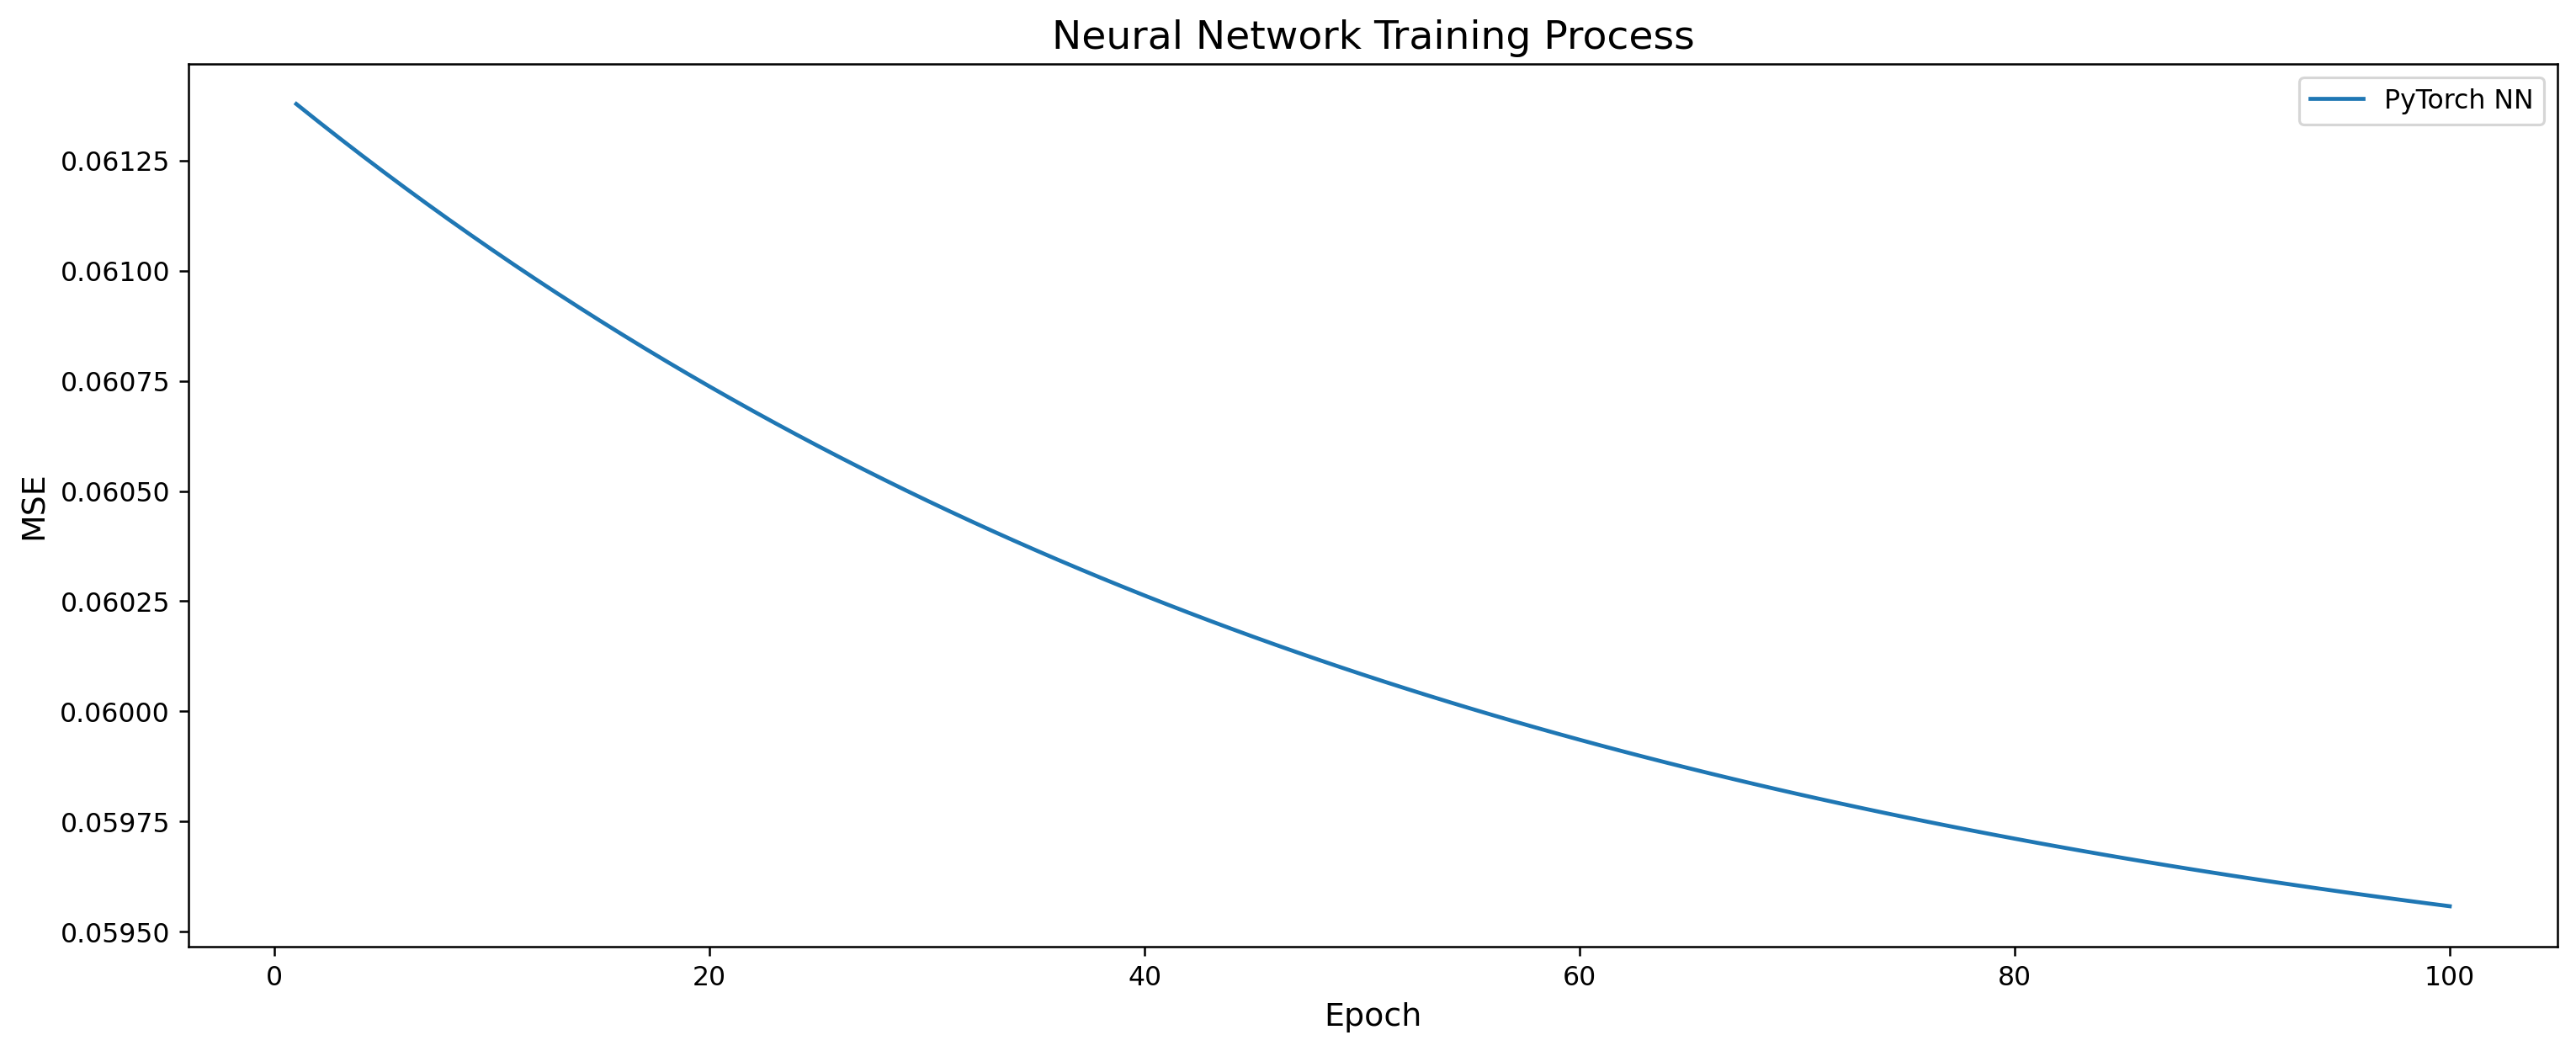

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing


housing_data = fetch_california_housing()
features = pd.DataFrame(housing_data.data, columns=housing_data.feature_names)
target = pd.DataFrame(housing_data.target, columns=['Target'])
df = features.join(target)
df.head()


scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[['MedInc', 'AveRooms', 'Target']])


X_train, X_test, y_train, y_test = train_test_split(
    df_scaled[:10000, :2],
    df_scaled[:10000, 2:],
    test_size=0.33,
    random_state=42
)

X_train.shape
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.fc1 = nn.Linear(2, 3)  
        self.fc2 = nn.Linear(3, 1)  
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.sigmoid(self.fc1(x))
        x = self.sigmoid(self.fc2(x))
        return x

model = SimpleNeuralNetwork()

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.05)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)


history = []  
for epoch in range(100):
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    history.append(loss.item())  
    print(f"Epoch: {epoch+1}, Loss: {loss.item()}")




X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_pred_tensor = model(X_test_tensor).detach().numpy()
mse = mean_squared_error(y_test, y_pred_tensor)
print(f"Test MSE: {mse}")


plt.rcParams['figure.dpi'] = 227
plt.rcParams['figure.figsize'] = (16, 6)
plt.plot(range(1, 101), history, label="PyTorch NN")
plt.title('Neural Network Training Process', fontsize=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.legend()
plt.show()

tensorflow

Epoch: 1, Loss: 0.061818718910217285
Epoch: 2, Loss: 0.06181767210364342
Epoch: 3, Loss: 0.06181662529706955
Epoch: 4, Loss: 0.06181558221578598
Epoch: 5, Loss: 0.06181453540921211
Epoch: 6, Loss: 0.061813484877347946
Epoch: 7, Loss: 0.06181244179606438
Epoch: 8, Loss: 0.06181139498949051
Epoch: 9, Loss: 0.06181034818291664
Epoch: 10, Loss: 0.06180930882692337
Epoch: 11, Loss: 0.0618082694709301
Epoch: 12, Loss: 0.06180722638964653
Epoch: 13, Loss: 0.061806175857782364
Epoch: 14, Loss: 0.06180513650178909
Epoch: 15, Loss: 0.061804093420505524
Epoch: 16, Loss: 0.061803046613931656
Epoch: 17, Loss: 0.061802007257938385
Epoch: 18, Loss: 0.06180096045136452
Epoch: 19, Loss: 0.061799921095371246
Epoch: 20, Loss: 0.061798885464668274
Epoch: 21, Loss: 0.061797846108675
Epoch: 22, Loss: 0.06179680675268173
Epoch: 23, Loss: 0.06179576367139816
Epoch: 24, Loss: 0.06179472431540489
Epoch: 25, Loss: 0.06179368123412132
Epoch: 26, Loss: 0.06179264187812805
Epoch: 27, Loss: 0.061791613698005676
Epoc

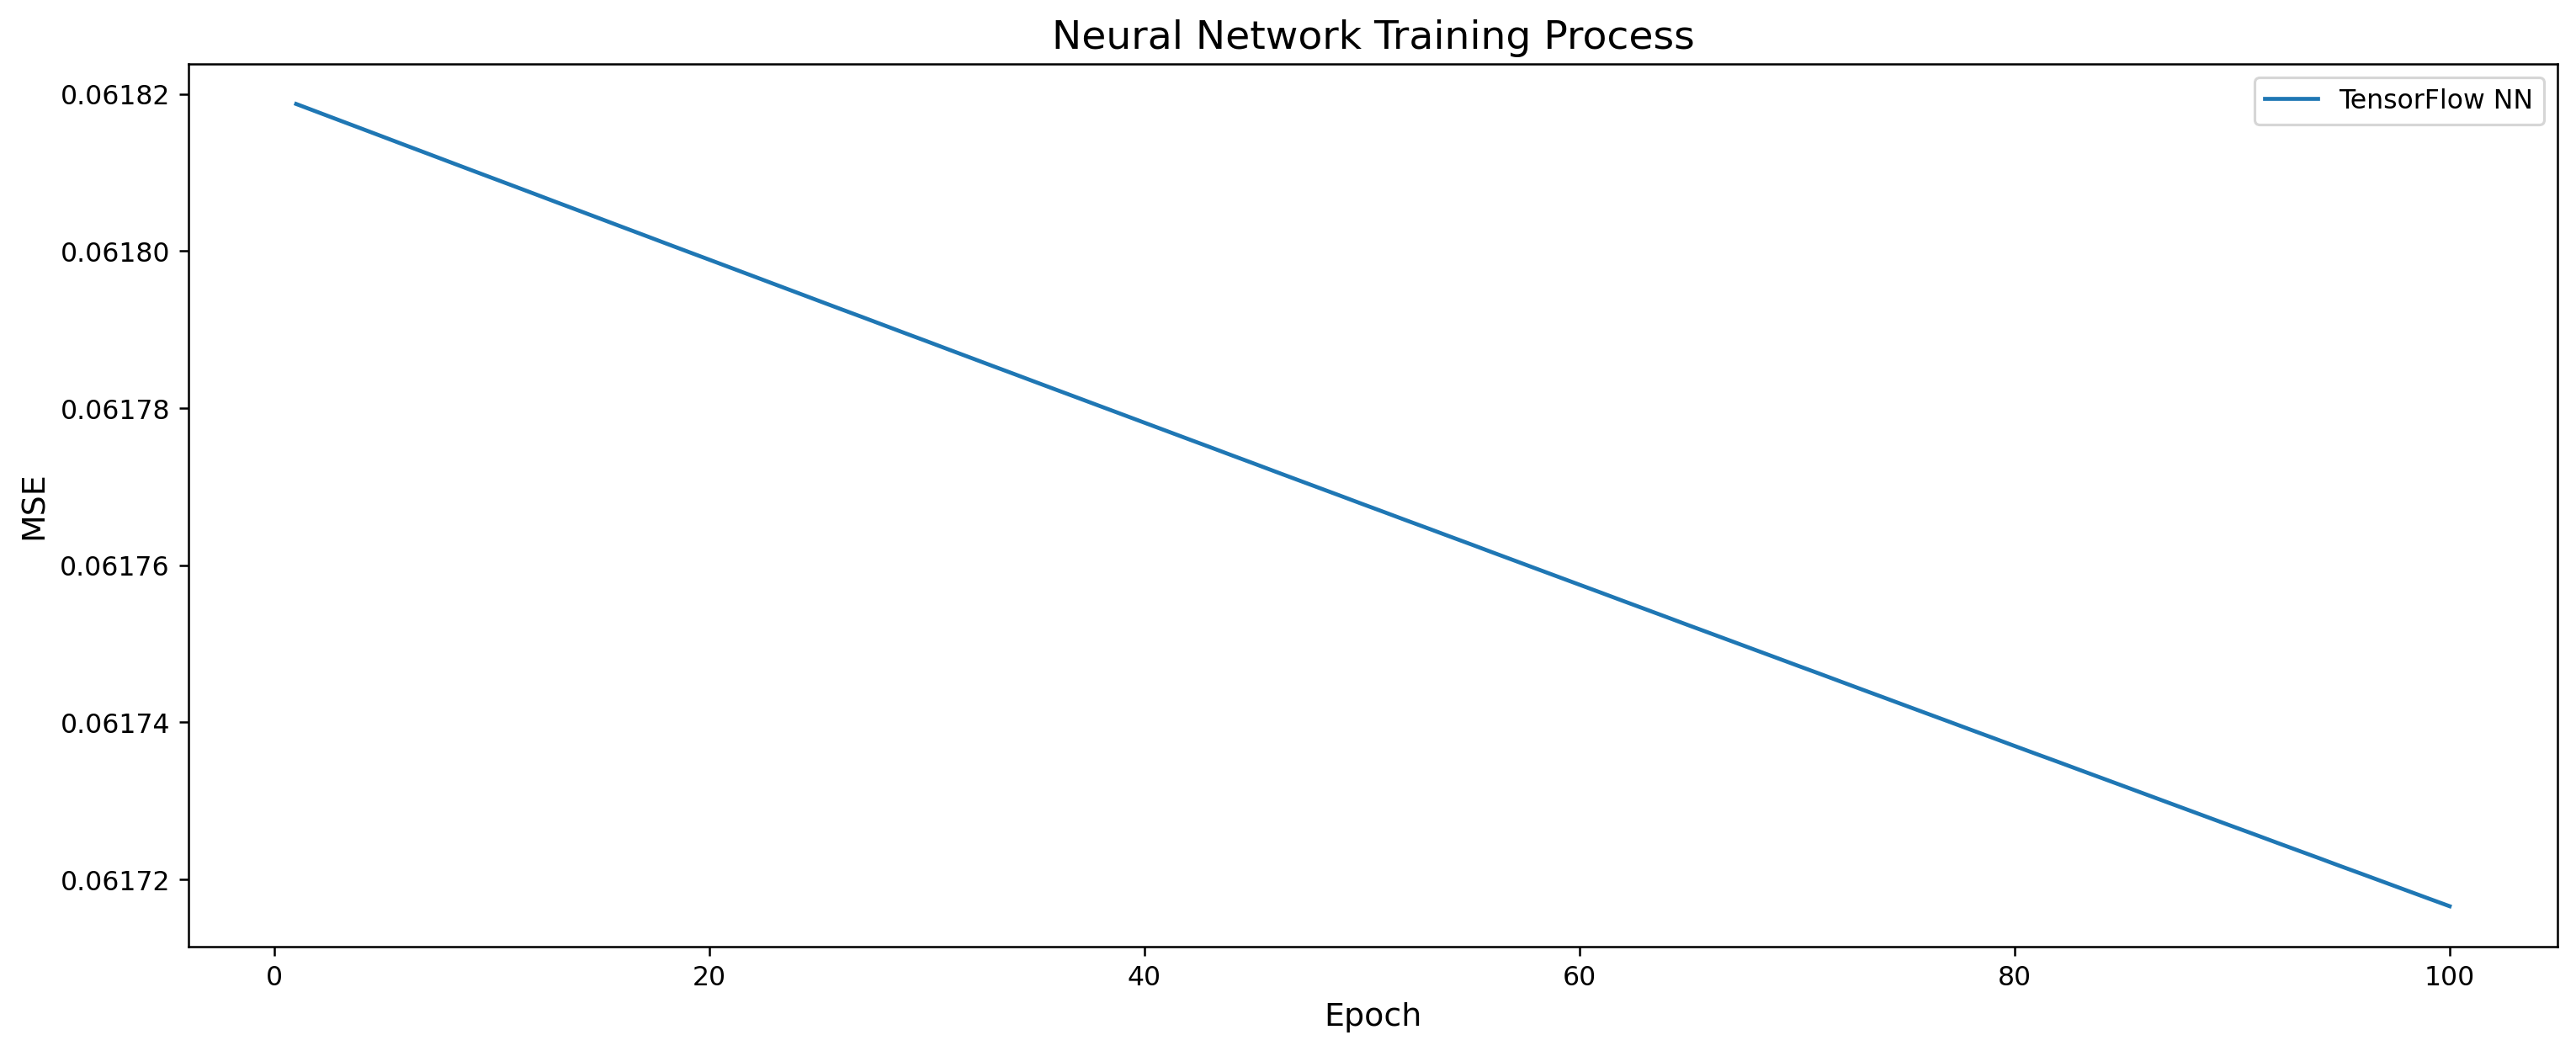

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing


housing_data = fetch_california_housing()
features = pd.DataFrame(housing_data.data, columns=housing_data.feature_names)
target = pd.DataFrame(housing_data.target, columns=['Target'])
df = features.join(target)
df.head()

scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[['MedInc', 'AveRooms', 'Target']])

X_train, X_test, y_train, y_test = train_test_split(
    df_scaled[:10000, :2],
    df_scaled[:10000, 2:],
    test_size=0.33,
    random_state=42
)

X_train.shape

class SimpleNeuralNetwork(tf.keras.Model):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.fc1 = tf.keras.layers.Dense(3, activation='sigmoid')  
        self.fc2 = tf.keras.layers.Dense(1, activation='sigmoid')  

    def call(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        return x


model = SimpleNeuralNetwork()


criterion = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.SGD(learning_rate=0.05)


X_train_tensor = tf.convert_to_tensor(X_train, dtype=tf.float32)
y_train_tensor = tf.convert_to_tensor(y_train, dtype=tf.float32)


history = [] 
for epoch in range(100):
    with tf.GradientTape() as tape:
        outputs = model(X_train_tensor)
        loss = criterion(y_train_tensor, outputs)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    history.append(loss.numpy())
    print(f"Epoch: {epoch+1}, Loss: {loss.numpy()}")


X_test_tensor = tf.convert_to_tensor(X_test, dtype=tf.float32)
y_pred_tensor = model(X_test_tensor).numpy()
mse = mean_squared_error(y_test, y_pred_tensor)
print(f"Test MSE: {mse}")

plt.rcParams['figure.dpi'] = 227
plt.rcParams['figure.figsize'] = (16, 6)
plt.plot(range(1, 101), history, label="TensorFlow NN")
plt.title('Neural Network Training Process', fontsize=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.legend()
plt.show()